In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [2]:
dataset_path=r"C:\Users\Shardul\OneDrive\Desktop\CS Datasets\05_real_and_fake_face"

In [3]:
x=[]
y=[]

In [4]:
extensions=(".jpg",".jpeg",".png",".webp",".bmp")

In [5]:
def load_folder(folder,label):
    for file in os.listdir(folder):
        img=cv2.imread(os.path.join(folder,file))
        if img is None:
            continue
        img=cv2.resize(img,(64,64))
        img=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
        x.append(img.flatten()/255.0)
        y.append(label)
load_folder(os.path.join(dataset_path, "training_real"), 1)
load_folder(os.path.join(dataset_path, "training_fake"), 0)

x,y=np.array(x),np.array(y)

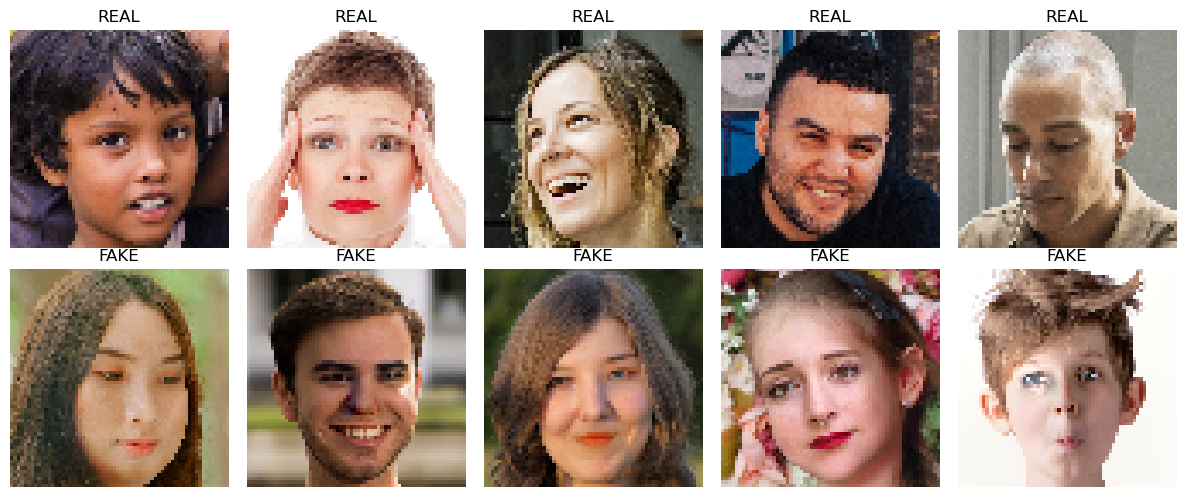

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

real_idx = np.where(y==1)[0][:5]
fake_idx = np.where(y==0)[0][:5]

for i in range(5):
    axes[0, i].imshow(x[real_idx[i]].reshape(64, 64, 3))
    axes[0, i].set_title("REAL")
    axes[0, i].axis("off")

    axes[1, i].imshow(x[fake_idx[i]].reshape(64, 64, 3))
    axes[1, i].set_title("FAKE")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [7]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y)

In [8]:
model = SVC(kernel="linear")
model.fit(x_train, y_train)
print("Training done")

Training done


In [9]:
y_pred = model.predict(x_test)

In [10]:
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", round(acc*100, 2), "%")

print(classification_report(y_test, y_pred, target_names=["Fake", "Real"]))

Accuracy: 58.44 %
              precision    recall  f1-score   support

        Fake       0.56      0.58      0.57       192
        Real       0.61      0.59      0.60       217

    accuracy                           0.58       409
   macro avg       0.58      0.58      0.58       409
weighted avg       0.59      0.58      0.58       409



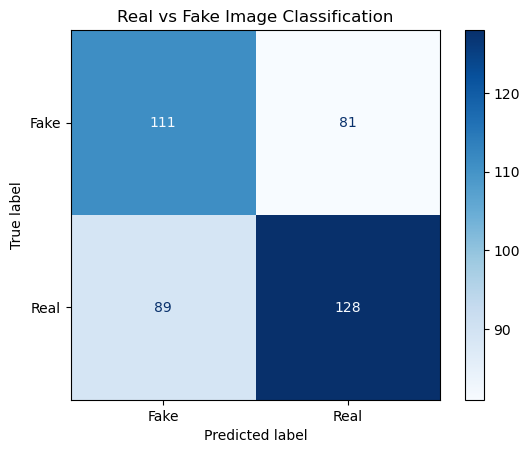

In [11]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Fake", "Real"]).plot(cmap="Blues")
plt.title("Real vs Fake Image Classification")
plt.show()